# Figure 3 Supplement 5: The bound collapses in every condition

The fitted bound time course (as in Figure 3C) for every condition of cohorts 1
and 2, with a test of the late part of the collapse in each condition.

**Fits** (`scripts/run_stopping_late_slope.py`): each subject's start height
(bound at step 1 relative to the plateau) and time of the fall to the plateau
are taken from their main fit to all of their data, as are sensory noise and
the non-decision time. Each condition's trials are then fit alone, with the
plateau, bound variability, guess, lapse and anticipation rates and the slope
of the bound after the fall free. The null model is the same with that slope
fixed at 0 (bound flat after the fall); the two are compared with a
likelihood-ratio test (χ², 1 df).

**Each panel:** every subject's bound relative to their plateau (thin blue), the
median across subjects (thick black), and the number of subjects whose bound
kept falling after the fall (slope < 0, p < 0.05) out of the subjects shown.
Each subject's curve is drawn only up to the `DT_QUANTILE` quantile of their
decision times in that condition, so slopes estimated from few long trials are
not extrapolated; the median is taken over the subjects whose curves reach each
step and stops where fewer than half of them do.

Rows: cohort 1 (blocked SNR) low-SNR blocks 1–3 and high-SNR blocks 4–6;
cohort 2 (mixed SNR) blocks 1–3, low-SNR and high-SNR trials. Columns: reward
conditions (no penalty, coin penalty, step penalty). Subject-conditions whose
plateau sits at a fit limit (`get_plateau_at_limit`) are left out (counts
printed).

Replaces Figure 3 – Table Supplement 1 (slopes of linear fits of the measured
bound vs. DT), which was the basis for the earlier conclusion that the bound
did not collapse.

In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC
from pigeon.stopping import get_log_h, get_plateau_at_limit, get_stopping_model_trials

PROCESSED = Path('../data/processed')

In [2]:
ALPHA = 0.05
STEPS = np.arange(1, 16)
DT_QUANTILE = 0.9
COLUMNS = ['No penalty', 'Coin penalty', 'Step penalty']
ROWS = [('Cohort 1, low SNR', 'OL', ['B1', 'B2', 'B3']),
        ('Cohort 1, high SNR', 'OL', ['B4', 'B5', 'B6']),
        ('Cohort 2, low-SNR trials', 'MX', ['B1_lo', 'B2_lo', 'B3_lo']),
        ('Cohort 2, high-SNR trials', 'MX', ['B1_hi', 'B2_hi', 'B3_hi'])]

late = pd.read_pickle(PROCESSED / 'stopping_late_slope.pkl')
main = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl').groupby(['task', 'subject_index']).first()
late = late.join(main[['log_h_start', 'knee']], on=['task', 'subject_index'])
print(f'{len(late)} subject x condition fits; raised: {int(late.error.notna().sum())}; '
      f'not converged: alternative {int((late.success_alt == False).sum())}, '  # noqa: E712
      f'null {int((late.success_null == False).sum())}')
# Each subject x condition's DT range, from the same trials the late-slope fits used
dt_max = {}
for task, blocks in {'OL': [1, 2, 3, 4, 5, 6], 'MX': [1, 2, 3]}.items():
    d = get_stopping_model_trials(task, blocks)
    if task == 'MX':
        lo = np.isclose(d.snr.abs(), d.snr.abs().min())
        d['condition'] = d.condition + np.where(lo, '_lo', '_hi')
    dt_max[task] = d.groupby(['subject_index', 'condition']).DT.quantile(DT_QUANTILE)
dt_max = pd.concat(dt_max, names=['task']).rename('dt_max')
late = late.join(dt_max, on=['task', 'subject_index', 'condition'])
late['at_limit'] = get_plateau_at_limit(late)
late['collapsing'] = (late.late_slope < 0) & (late.p_value < ALPHA)
late['rising'] = (late.late_slope > 0) & (late.p_value < ALPHA)

rows = []
for label, task, conds in ROWS:
    for col, cond in zip(COLUMNS, conds):
        g = late[(late.task == task) & (late.condition == cond)]
        k = g[~g.at_limit & g.error.isna()]
        change = np.exp(10 * k.late_slope) - 1
        rows.append({'row': label, 'column': col, 'subjects': len(k), 'excluded (plateau at limit)': int(g.at_limit.sum()),
                     'collapsing (slope < 0, p < 0.05)': int(k.collapsing.sum()),
                     'rising (slope > 0, p < 0.05)': int(k.rising.sum()),
                     'change per 10 steps, median [IQR]': f'{change.median():.3f} [{change.quantile(.25):.3f}, '
                                                          f'{change.quantile(.75):.3f}]',
                     'median trials': k.n_trials.median(),
                     f'median DT {DT_QUANTILE:.0%} quantile': k.dt_max.median()})
summary = pd.DataFrame(rows)
display(summary)

719 subject x condition fits; raised: 0; not converged: alternative 0, null 0


OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


MX: subjects with a good adaptation tau fit, by block: {1: 3, 2: 15, 3: 11}
MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 58 more in the adaptation transient, 182 more with no choice; 60 subjects


,row,column,subjects,excluded (plateau at limit),"collapsing (slope < 0, p < 0.05)","rising (slope > 0, p < 0.05)","change per 10 steps, median [IQR]",median trials,median DT 90% quantile
0,"Cohort 1, low SNR",No penalty,58,2,20,0,"-0.643 [-0.777, -0.273]",108.0,5.0
1,"Cohort 1, low SNR",Coin penalty,59,1,29,0,"-0.292 [-0.570, -0.137]",64.0,11.0
2,"Cohort 1, low SNR",Step penalty,57,2,20,0,"-0.348 [-0.777, -0.147]",33.0,8.0
3,"Cohort 1, high SNR",No penalty,53,7,2,0,"-0.777 [-0.777, 0.000]",146.0,2.0
4,"Cohort 1, high SNR",Coin penalty,59,1,3,1,"-0.265 [-0.777, 0.376]",121.0,4.0
5,"Cohort 1, high SNR",Step penalty,60,0,1,0,"-0.398 [-0.777, 0.200]",78.0,3.0
6,"Cohort 2, low-SNR trials",No penalty,60,0,10,1,"-0.541 [-0.777, 0.072]",57.5,4.9
7,"Cohort 2, low-SNR trials",Coin penalty,57,3,17,0,"-0.372 [-0.653, -0.192]",47.0,8.0
8,"Cohort 2, low-SNR trials",Step penalty,59,1,11,0,"-0.350 [-0.777, 0.000]",23.0,6.0
9,"Cohort 2, high-SNR trials",No penalty,59,1,4,1,"-0.618 [-0.777, 0.017]",56.0,4.0


/var/folders/v3/dxhd_9yn6sj19nbgkqkdb2m40000gn/T/ipykernel_54610/99394269.py:17: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(shapes, axis=0)
/var/folders/v3/dxhd_9yn6sj19nbgkqkdb2m40000gn/T/ipykernel_54610/99394269.py:17: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(shapes, axis=0)
/var/folders/v3/dxhd_9yn6sj19nbgkqkdb2m40000gn/T/ipykernel_54610/99394269.py:17: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(shapes, axis=0)
/var/folders/v3/dxhd_9yn6sj19nbgkqkdb2m40000gn/T/ipykernel_54610/99394269.py:17: RuntimeWarning: All-NaN slice encountered
  med = np.nanmedian(shapes, axis=0)


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


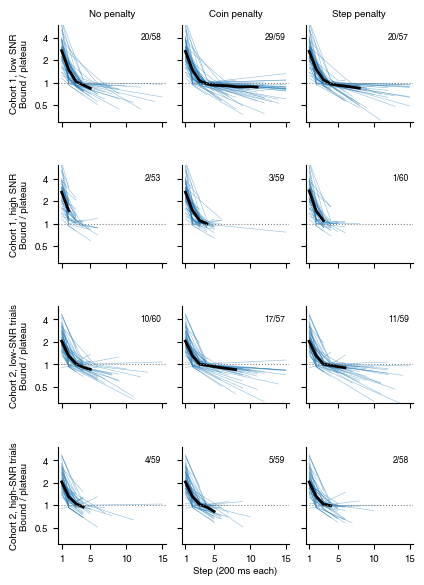

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S05.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'

fig = plt.figure(figsize=(11 * CM, 15 * CM))
gs = gridspec.GridSpec(len(ROWS), 3, figure=fig, hspace=0.45, wspace=0.15, left=0.17, right=0.99,
                       bottom=0.07, top=0.95)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(len(ROWS))])
for r, (label, task, conds) in enumerate(ROWS):
    for c, (col, cond) in enumerate(zip(COLUMNS, conds)):
        ax = axes[r, c]
        k = late[(late.task == task) & (late.condition == cond) & ~late.at_limit & late.error.isna()]
        shapes = np.exp(get_log_h(k, STEPS))
        shapes[STEPS[None, :] > k.dt_max.to_numpy()[:, None]] = np.nan   # only where the subject has trials
        ax.plot(STEPS, shapes.T, color=MODEL, lw=0.4, alpha=0.5)
        med = np.nanmedian(shapes, axis=0)
        med[np.isfinite(shapes).sum(axis=0) < len(k) / 2] = np.nan
        ax.plot(STEPS, med, 'k-', lw=2)
        ax.axhline(1, color='0.5', ls=':', lw=0.8)
        ax.text(0.96, 0.92, f'{int(k.collapsing.sum())}/{len(k)}', transform=ax.transAxes, ha='right', va='top',
                fontsize=6)
        ax.set_yscale('log')
        ax.set_ylim(0.3, 6)
        ax.set_yticks([0.5, 1, 2, 4])
        ax.set_yticklabels(['0.5', '1', '2', '4'] if c == 0 else [])
        ax.minorticks_off()
        ax.set_xlim(0.5, 15.5)
        ax.set_xticks([1, 5, 10, 15])
        if r < len(ROWS) - 1:
            ax.set_xticklabels([])
        if r == 0:
            ax.set_title(col)
        if c == 0:
            ax.set_ylabel(f'{label}\nBound / plateau')
        ax.spines[['top', 'right']].set_visible(False)

fig.canvas.draw()
left, right = axes[-1, 0].get_position().x0, axes[-1, -1].get_position().x1
bottom = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in axes[-1])
fig.text((left + right) / 2, bottom - 0.005, 'Step (200 ms each)', ha='center', va='top', fontsize=FS)

out = FIGURES_DIR / 'Figure03_S05.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')

## Interpretation

(Filled in after review.)